In [2]:
# Telecom Churn Intelligence Platform

## 01 — Exploratory Data Analysis

# This notebook explores the telecom customer churn dataset,
# understands the structure and quality of the data, and identifies
# patterns that will guide preprocessing and machine learning.

In [3]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\HP\Desktop\telecom-churn-intelligence\.venv\Scripts\python.exe
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import pandas as pd

df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [6]:
df.shape

(7043, 33)

In [7]:
df.columns 

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [9]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [10]:
missing = df.isnull().sum()

missing_percentage = (missing/len(df))*100

missing_percentage[missing_percentage > 0]

Churn Reason    73.463013
dtype: float64

In [11]:
df["Churn Label"].value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

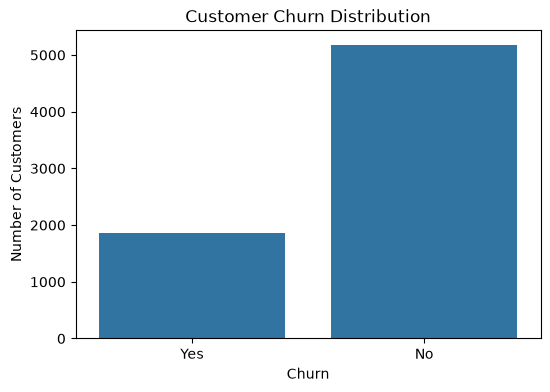

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (6,4))

sns.countplot(data=df, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [13]:
numerical_columns = df.select_dtypes(include=["int64","float64"]).columns
category_columns = df.select_dtypes(["object"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

print("Categorical columns:")
print(category_columns.tolist())

Numerical columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']
Categorical columns:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Label', 'Churn Reason']


C:\Users\HP\AppData\Local\Temp\ipykernel_14960\1507676235.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_columns = df.select_dtypes(["object"]).columns


In [14]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


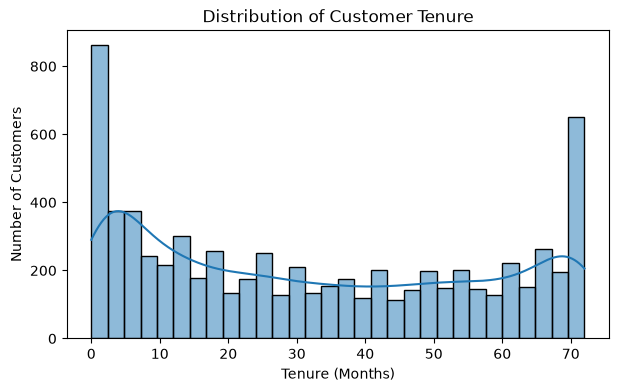

In [15]:
plt.figure(figsize=(7,4))

sns.histplot(data=df, x="Tenure Months",bins=30,kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


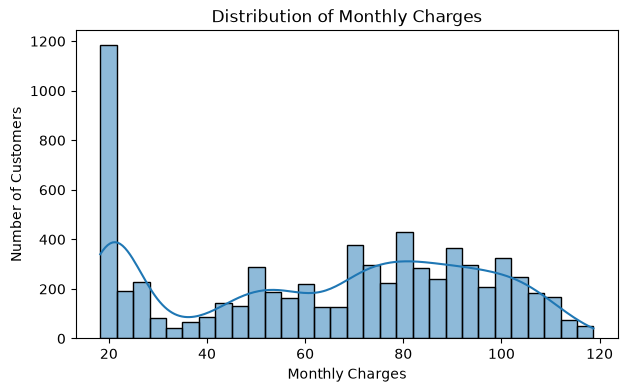

In [16]:
plt.figure(figsize=(7,4))

sns.histplot(data=df,x="Monthly Charges", bins = 30, kde = True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
df["Total Charges"].dtype

dtype('O')

In [18]:
df["Total Charges"].head(20)

0      108.15
1      151.65
2       820.5
3     3046.05
4      5036.3
5      528.35
6       39.65
7       20.15
8     4749.15
9        30.2
10     1093.1
11      316.9
12    3549.25
13     1105.4
14     144.15
15     1426.4
16      633.3
17    1752.55
18     857.25
19      79.35
Name: Total Charges, dtype: object

In [19]:
df[df["Total Charges"].str.strip() == ""]["Total Charges"].value_counts()

Total Charges
    11
Name: count, dtype: int64

In [20]:
df["Total Charges"].isna().sum()

np.int64(0)

In [21]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [22]:
df["Total Charges"].dtype

dtype('float64')

In [23]:
print(df["Total Charges"].isnull().sum())


11


In [24]:
missing_total = df[df["Total Charges"].isna()]

missing_total[["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]]

,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,NaN
2438,3115-CZMZD,0,20.25,NaN
2568,5709-LVOEQ,0,80.85,NaN
2667,4367-NUYAO,0,25.75,NaN
2856,1371-DWPAZ,0,56.05,NaN
4331,7644-OMVMY,0,19.85,NaN
4687,3213-VVOLG,0,25.35,NaN
5104,2520-SGTTA,0,20.00,NaN
5719,2923-ARZLG,0,19.70,NaN
6772,4075-WKNIU,0,73.35,NaN


In [25]:
missing_total["Tenure Months"].value_counts()

Tenure Months
0    11
Name: count, dtype: int64

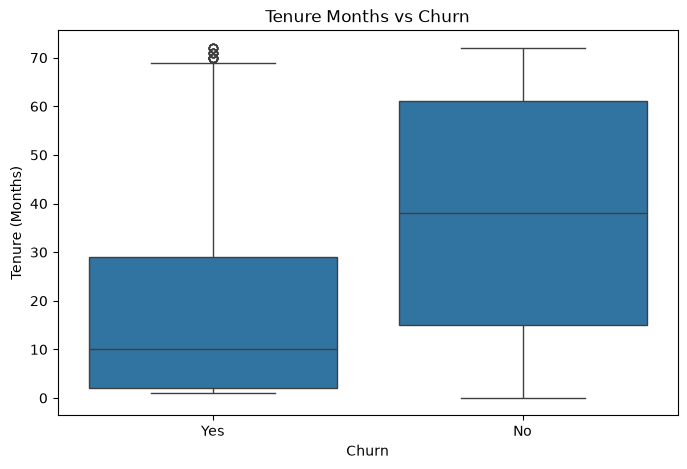

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Tenure Months vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [27]:
df.groupby("Churn Label")["Tenure Months"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,37.569965,38.0,0,72
Yes,1869,17.979133,10.0,1,72


In [28]:
df.groupby("Churn Label")["Monthly Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


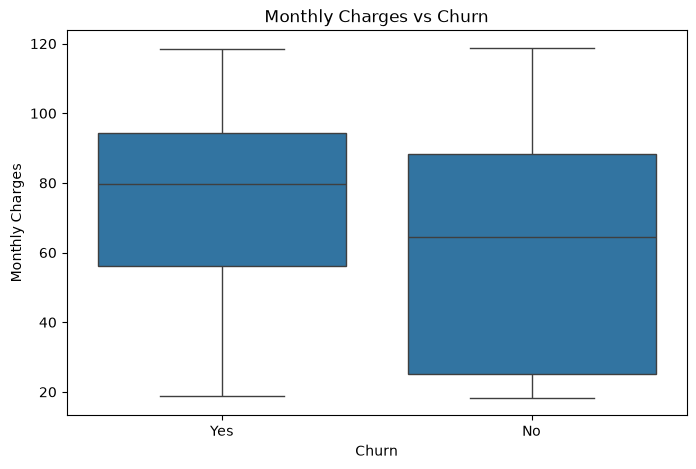

In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data = df,
    x = "Churn Label",
    y = "Monthly Charges"
)

plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.title("Monthly Charges vs Churn")

plt.show()

In [30]:
df.groupby("Churn Label")["Monthly Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


In [31]:
df.groupby("Contract")["Churn Label"].value_counts()

Contract        Churn Label
Month-to-month  No             2220
                Yes            1655
One year        No             1307
                Yes             166
Two year        No             1647
                Yes              48
Name: count, dtype: int64

In [32]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

contract_churn

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


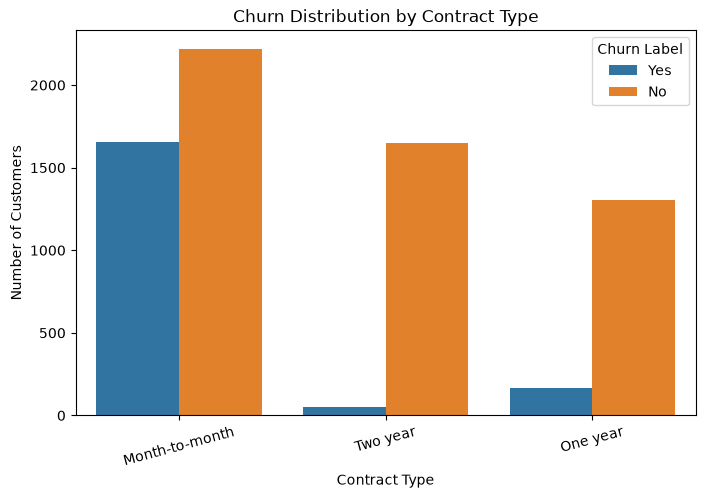

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [34]:
internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize="index"
) * 100

internet_churn

Churn Label,No,Yes
Internet Service,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Internet Service type is strongly associated with churn in this dataset, with fiber-optic customers showing a substantially higher observed churn rate than DSL and customers without internet service.

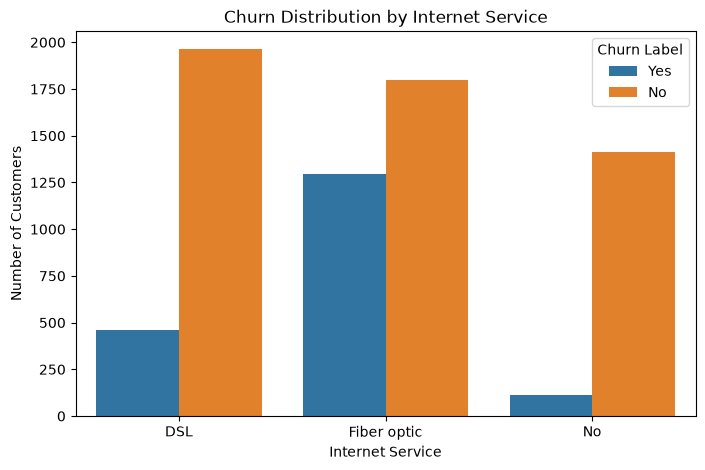

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Internet Service",
    hue="Churn Label"
)

plt.title("Churn Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [36]:
payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize="index"
) * 100

payment_churn

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Payment method is associated with churn, with electronic-check customers showing a substantially higher observed churn rate than customers using the other payment methods.

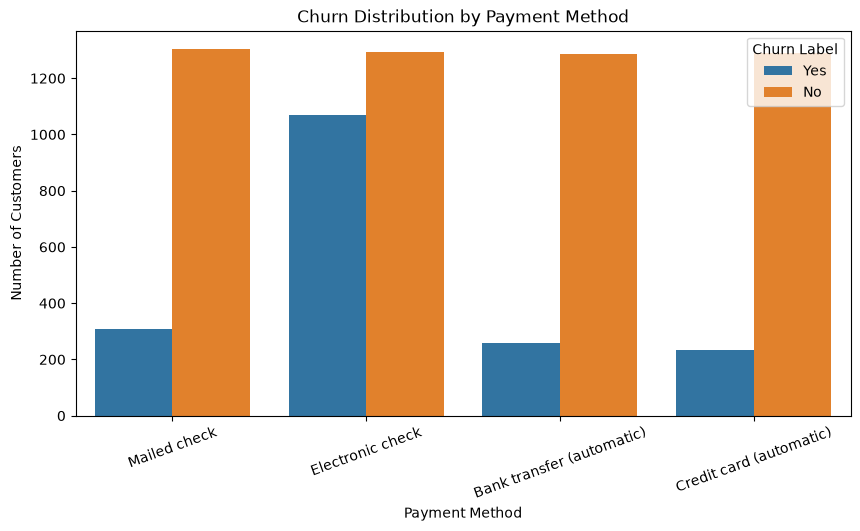

In [37]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Payment Method",
    hue="Churn Label"
)

plt.title("Churn Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [38]:
tech_churn = pd.crosstab(
    df["Tech Support"],
    df["Churn Label"],
    normalize="index"
) * 100

tech_churn

Churn Label,No,Yes
Tech Support,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


<function matplotlib.pyplot.show(close=None, block=None)>

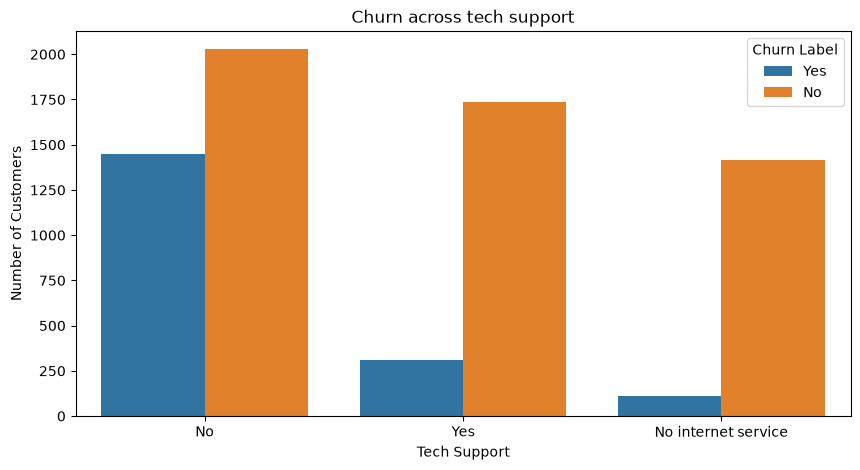

In [39]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Tech Support",
    hue = "Churn Label"
)

plt.title("Churn across tech support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show

Tech Support availability is strongly associated with churn in this dataset. Customers without tech support show a substantially higher observed churn rate than customers with tech support.

In [40]:
security_churn = pd.crosstab(
    df["Online Security"],
    df["Churn Label"],
    normalize="index"
)*100
security_churn

Churn Label,No,Yes
Online Security,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


<function matplotlib.pyplot.show(close=None, block=None)>

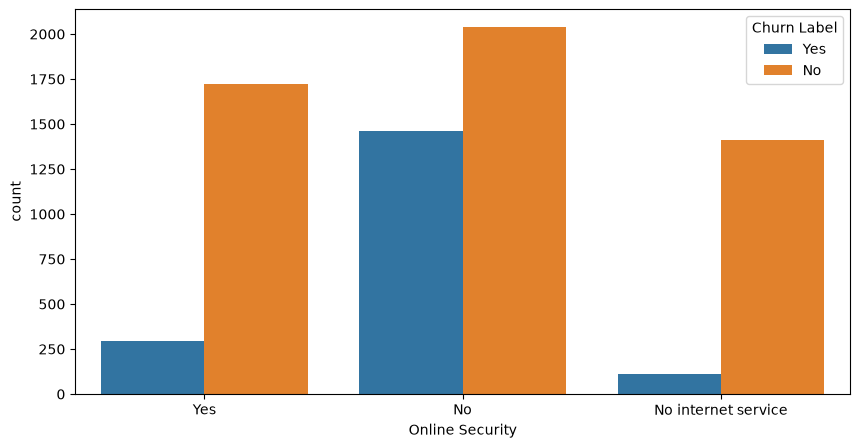

In [41]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Online Security",
    hue = "Churn Label"
)


plt.show

Online Security is strongly associated with churn in this dataset. Customers without online security show a substantially higher observed churn rate than customers with online security.

In [42]:
backup_churn = pd.crosstab(
    df["Online Backup"],
    df["Churn Label"],
    normalize="index"
)*100
backup_churn

Churn Label,No,Yes
Online Backup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


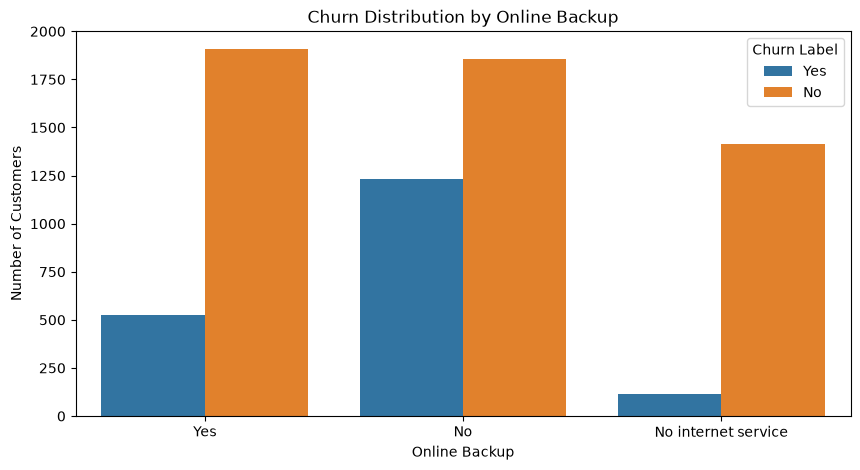

In [43]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Online Backup",
    hue = "Churn Label"
)
plt.title("Churn Distribution by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Number of Customers")

plt.show()

In [44]:
device_churn = pd.crosstab(
    df["Device Protection"],
    df["Churn Label"],
    normalize="index"
) * 100

device_churn

Churn Label,No,Yes
Device Protection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


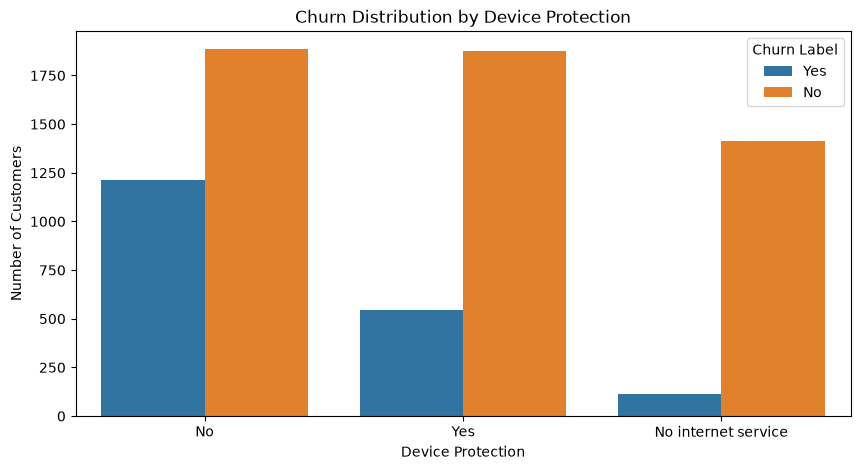

In [45]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Device Protection",
    hue="Churn Label"
)

plt.title("Churn Distribution by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Number of Customers")

plt.show()

In [46]:
multiple_lines_churn = pd.crosstab(
    df["Multiple Lines"],
    df["Churn Label"],
    normalize="index"
) * 100

multiple_lines_churn

Churn Label,No,Yes
Multiple Lines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


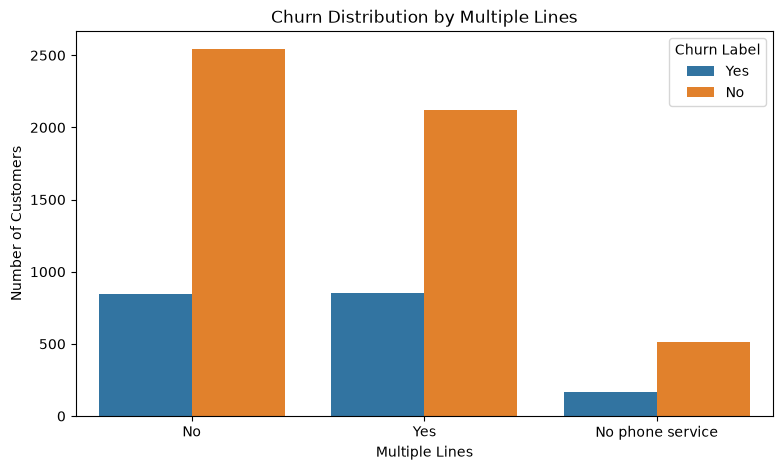

In [47]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x="Multiple Lines",
    hue="Churn Label"
)

plt.title("Churn Distribution by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Number of Customers")
plt.show()

In [48]:
phone_churn = pd.crosstab(
    df["Phone Service"],
    df["Churn Label"],
    normalize="index"
) * 100

phone_churn

Churn Label,No,Yes
Phone Service,,
No,75.073314,24.926686
Yes,73.290363,26.709637


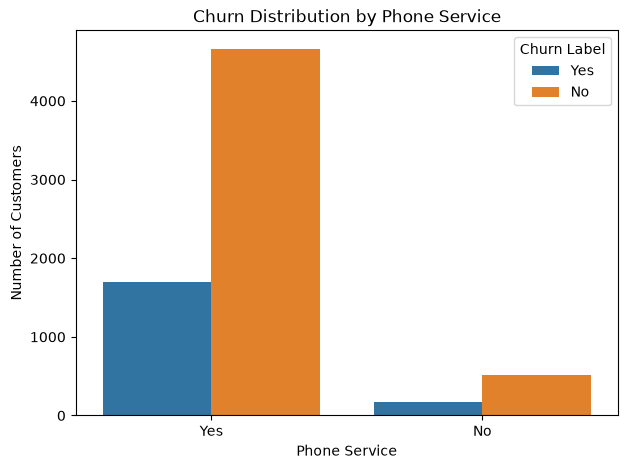

In [49]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Phone Service",
    hue="Churn Label"
)

plt.title("Churn Distribution by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Number of Customers")
plt.show()

In [50]:
paperless_churn = pd.crosstab(
    df["Paperless Billing"],
    df["Churn Label"],
    normalize="index"
) * 100

paperless_churn

Churn Label,No,Yes
Paperless Billing,,
No,83.669916,16.330084
Yes,66.434908,33.565092


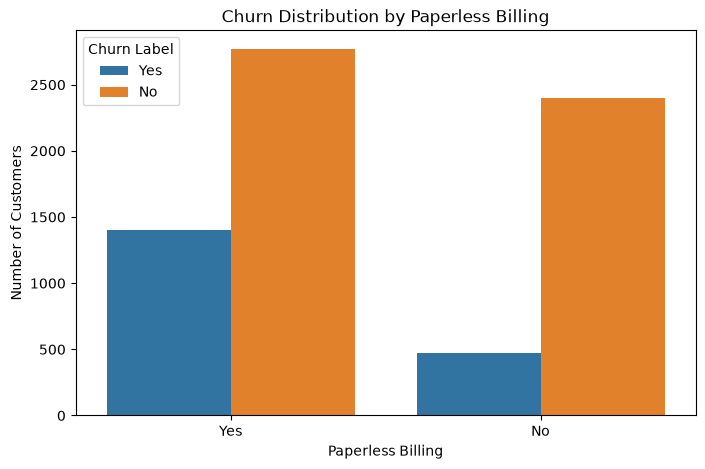

In [51]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Paperless Billing",
    hue="Churn Label"
)

plt.title("Churn Distribution by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.show()

In [52]:
senior_churn = pd.crosstab(
    df["Senior Citizen"],
    df["Churn Label"],
    normalize="index"
) * 100

senior_churn

Churn Label,No,Yes
Senior Citizen,,
No,76.393832,23.606168
Yes,58.318739,41.681261


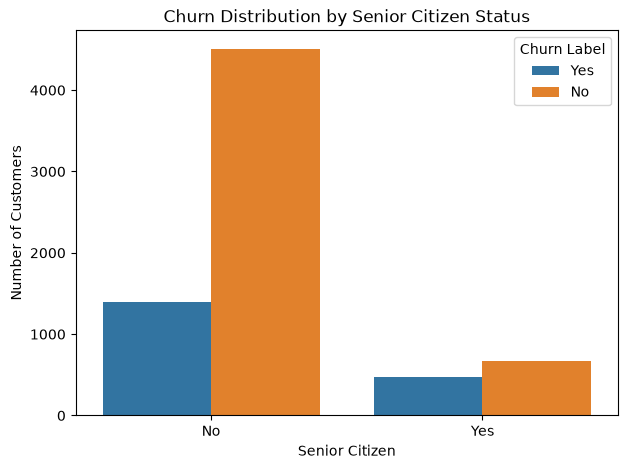

In [53]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Senior Citizen",
    hue="Churn Label"
)

plt.title("Churn Distribution by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.show()

In [54]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn Label"],
    normalize="index"
) * 100

partner_churn

Churn Label,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


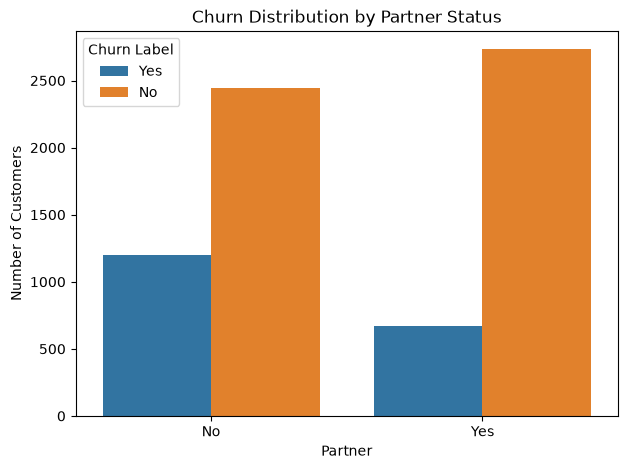

In [55]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn Label"
)

plt.title("Churn Distribution by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")
plt.show()

In [56]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn Label"],
    normalize="index"
) * 100

dependents_churn

Churn Label,No,Yes
Dependents,,
No,67.448301,32.551699
Yes,93.484942,6.515058


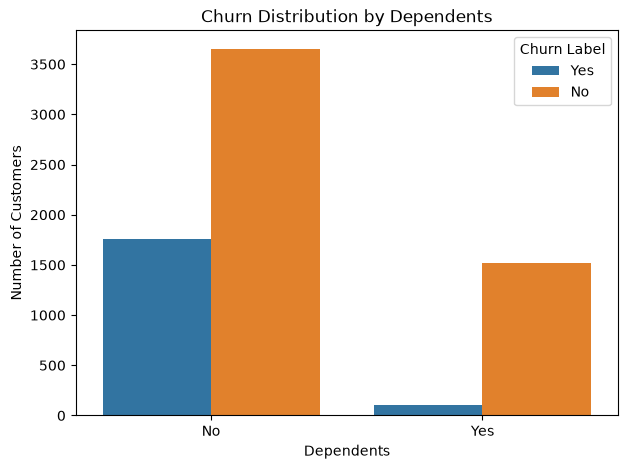

In [57]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Dependents",
    hue="Churn Label"
)

plt.title("Churn Distribution by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")
plt.show()

In [58]:
gender_churn = pd.crosstab(
    df["Gender"],
    df["Churn Label"],
    normalize="index"
) * 100

gender_churn

Churn Label,No,Yes
Gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


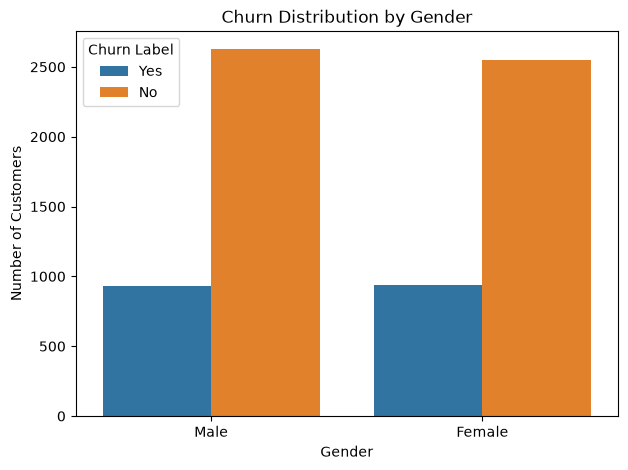

In [59]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Churn Label"
)

plt.title("Churn Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

In [60]:
senior_churn = pd.crosstab(
    df["Senior Citizen"],
    df["Churn Label"],
    normalize="index"
) * 100

senior_churn

Churn Label,No,Yes
Senior Citizen,,
No,76.393832,23.606168
Yes,58.318739,41.681261


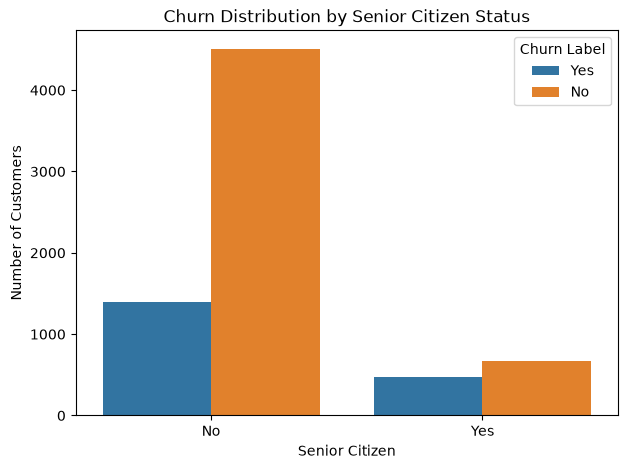

In [61]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Senior Citizen",
    hue="Churn Label"
)

plt.title("Churn Distribution by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.show()

In [64]:
df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [63]:
tenure_group_churn = pd.crosstab(
    df["Tenure Group"],
    df["Churn Label"],
    normalize="index"
) * 100

tenure_group_churn

Churn Label,No,Yes
Tenure Group,,
0-6 Months,47.062795,52.937205
7-12 Months,64.113475,35.886525
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-72 Months,90.486824,9.513176


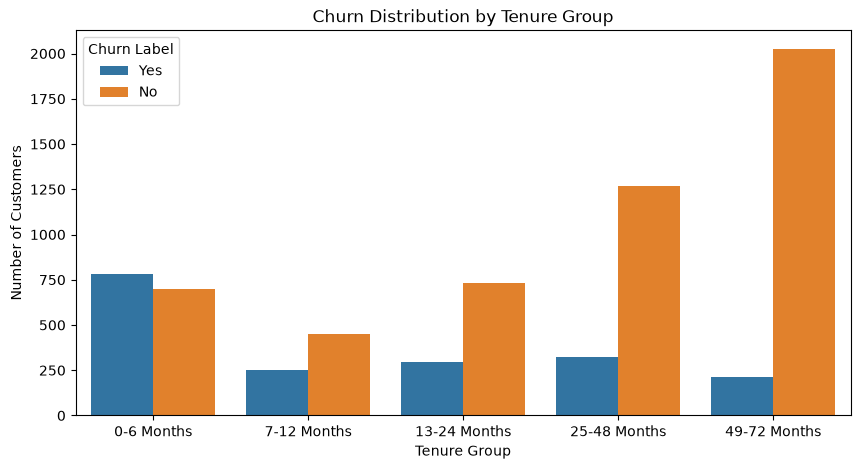

In [65]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Tenure Group",
    hue="Churn Label"
)

plt.title("Churn Distribution by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.show()

In [66]:
df["Monthly Charges Group"] = pd.cut(
    df["Monthly Charges"],
    bins=[0, 30, 60, 90, 120],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

In [67]:
monthly_charge_churn = pd.crosstab(
    df["Monthly Charges Group"],
    df["Churn Label"],
    normalize="index"
) * 100

monthly_charge_churn

Churn Label,No,Yes
Monthly Charges Group,,
Low,90.199637,9.800363
Medium,74.071146,25.928854
High,66.093881,33.906119
Very High,67.222542,32.777458


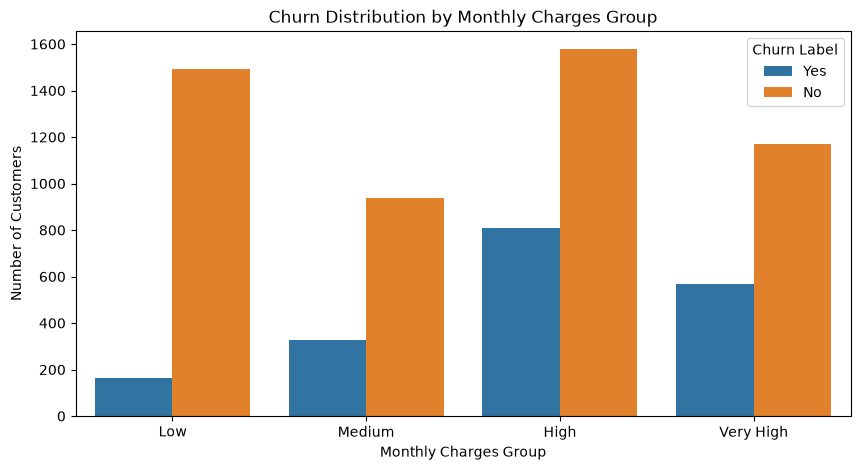

In [68]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Monthly Charges Group",
    hue="Churn Label"
)

plt.title("Churn Distribution by Monthly Charges Group")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Number of Customers")
plt.show()

In [70]:
service_columns = [
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

df["Service Count"] = (
    df[service_columns]
    .apply(lambda row: (row == "Yes").sum(), axis=1)
)

In [71]:
service_count_churn = pd.crosstab(
    df["Service Count"],
    df["Churn Label"],
    normalize="index"
) * 100

service_count_churn

Churn Label,No,Yes
Service Count,,
0,78.593961,21.406039
1,54.244306,45.755694
2,64.181994,35.818006
3,72.629696,27.370304
4,77.699531,22.300469
5,87.565674,12.434326
6,94.718310,5.281690


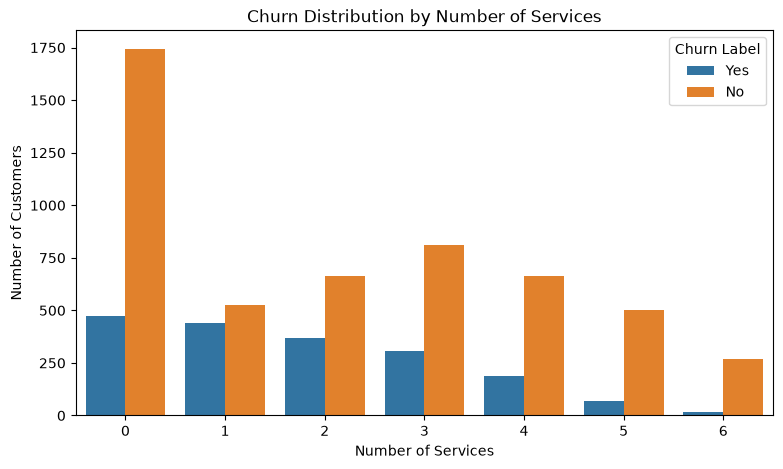

In [72]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Service Count",
    hue="Churn Label"
)

plt.title("Churn Distribution by Number of Services")
plt.xlabel("Number of Services")
plt.ylabel("Number of Customers")
plt.show()

In [73]:
contract_internet_churn = pd.crosstab(
    [df["Contract"], df["Internet Service"]],
    df["Churn Label"],
    normalize="index"
) * 100

contract_internet_churn

Churn Label                             No        Yes
Contract       Internet Service                      
Month-to-month DSL               67.784137  32.215863
               Fiber optic       45.394737  54.605263
               No                81.106870  18.893130
One year       DSL               90.701754   9.298246
               Fiber optic       80.705009  19.294991
               No                97.527473   2.472527
Two year       DSL               98.089172   1.910828
               Fiber optic       92.773893   7.226107
               No                99.216301   0.783699

AttributeError: Rectangle.set() got an unexpected keyword argument 'col'

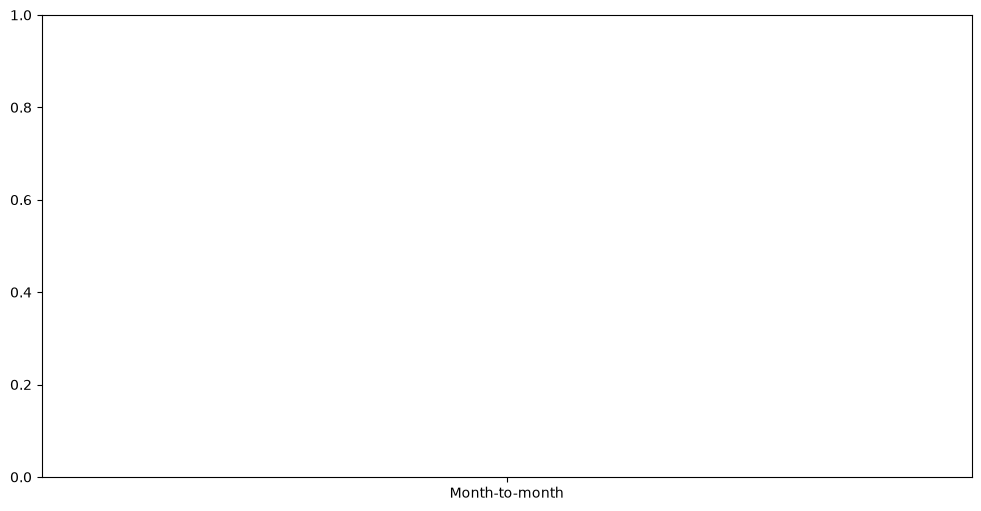

In [75]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Internet Service",
    col=None
)

plt.title("Internet Service Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

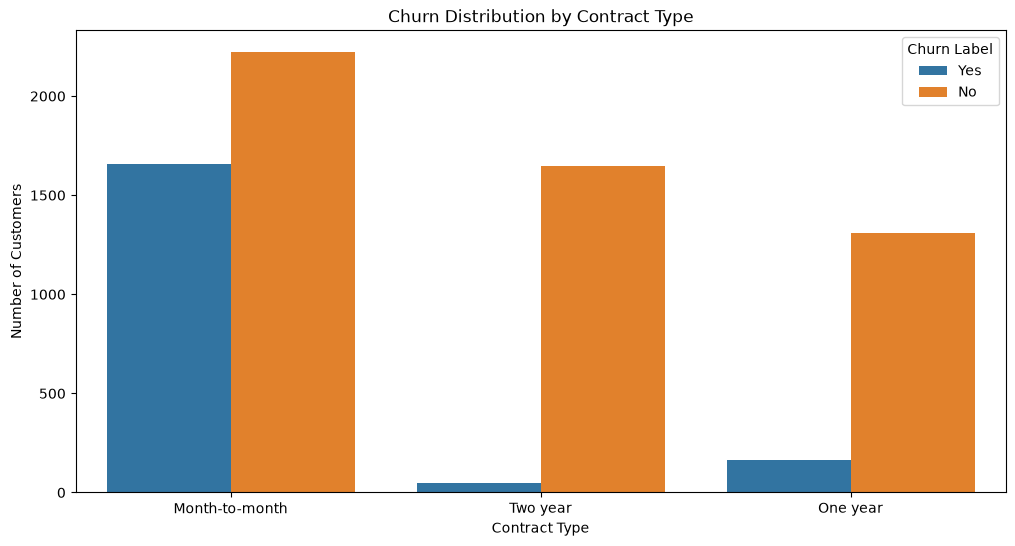

In [76]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

In [77]:
contract_payment_churn = pd.crosstab(
    [df["Contract"], df["Payment Method"]],
    df["Churn Label"],
    normalize="index"
) * 100

contract_payment_churn

Churn Label                                      No        Yes
Contract       Payment Method                                 
Month-to-month Bank transfer (automatic)  65.874363  34.125637
               Credit card (automatic)    67.219153  32.780847
               Electronic check           46.270270  53.729730
               Mailed check               68.421053  31.578947
One year       Bank transfer (automatic)  90.281330   9.718670
               Credit card (automatic)    89.698492  10.301508
               Electronic check           81.556196  18.443804
               Mailed check               93.175074   6.824926
Two year       Bank transfer (automatic)  96.631206   3.368794
               Credit card (automatic)    97.762478   2.237522
               Electronic check           92.261905   7.738095
               Mailed check               99.214660   0.785340

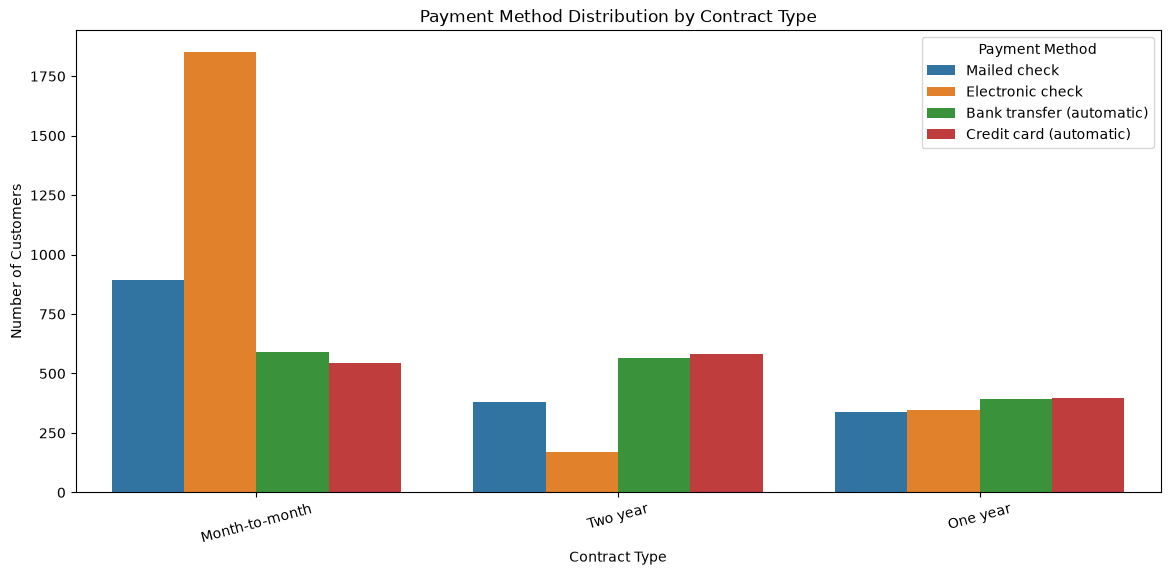

In [78]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Payment Method"
)

plt.title("Payment Method Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.legend(title="Payment Method")
plt.show()

In [79]:
contract_tenure_churn = pd.crosstab(
    [df["Contract"], df["Tenure Group"]],
    df["Churn Label"],
    normalize="index"
) * 100

contract_tenure_churn

Churn Label                          No        Yes
Contract       Tenure Group                       
Month-to-month 0-6 Months     44.798301  55.201699
               7-12 Months    58.003442  41.996558
               13-24 Months   62.279512  37.720488
               25-48 Months   67.082294  32.917706
               49-72 Months   73.976608  26.023392
One year       0-6 Months     89.743590  10.256410
               7-12 Months    89.411765  10.588235
               13-24 Months   91.878173   8.121827
               25-48 Months   89.382239  10.617761
               49-72 Months   87.066246  12.933754
Two year       0-6 Months    100.000000   0.000000
               7-12 Months   100.000000   0.000000
               13-24 Months  100.000000   0.000000
               25-48 Months   97.810219   2.189781
               49-72 Months   96.674584   3.325416

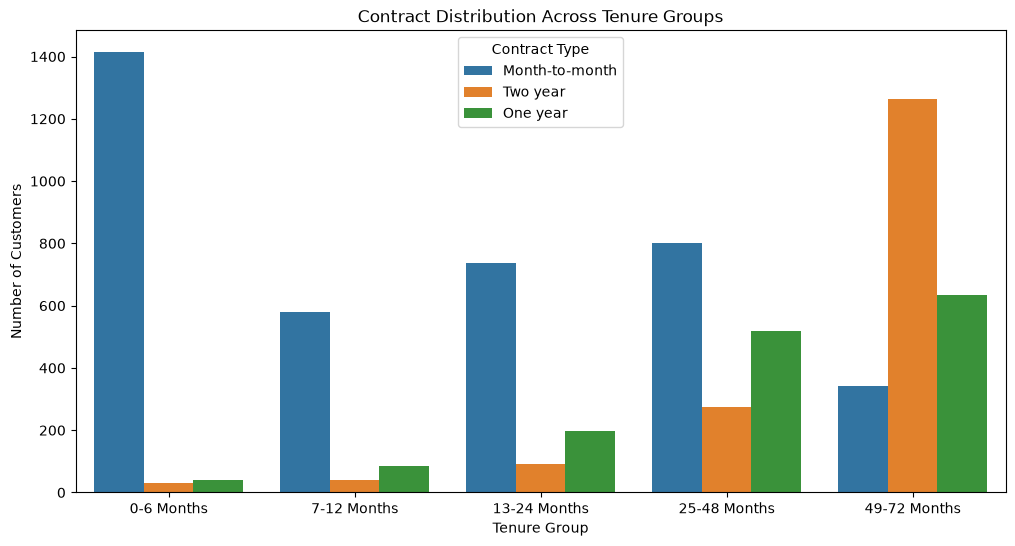

In [80]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Tenure Group",
    hue="Contract"
)

plt.title("Contract Distribution Across Tenure Groups")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.legend(title="Contract Type")
plt.show()

In [81]:
internet_support_churn = pd.crosstab(
    [df["Internet Service"], df["Tech Support"]],
    df["Churn Label"],
    normalize="index"
) * 100

internet_support_churn

Churn Label                                  No        Yes
Internet Service Tech Support                             
DSL              No                   72.244570  27.755430
                 Yes                  90.322581   9.677419
Fiber optic      No                   50.627803  49.372197
                 Yes                  77.367206  22.632794
No               No internet service  92.595020   7.404980

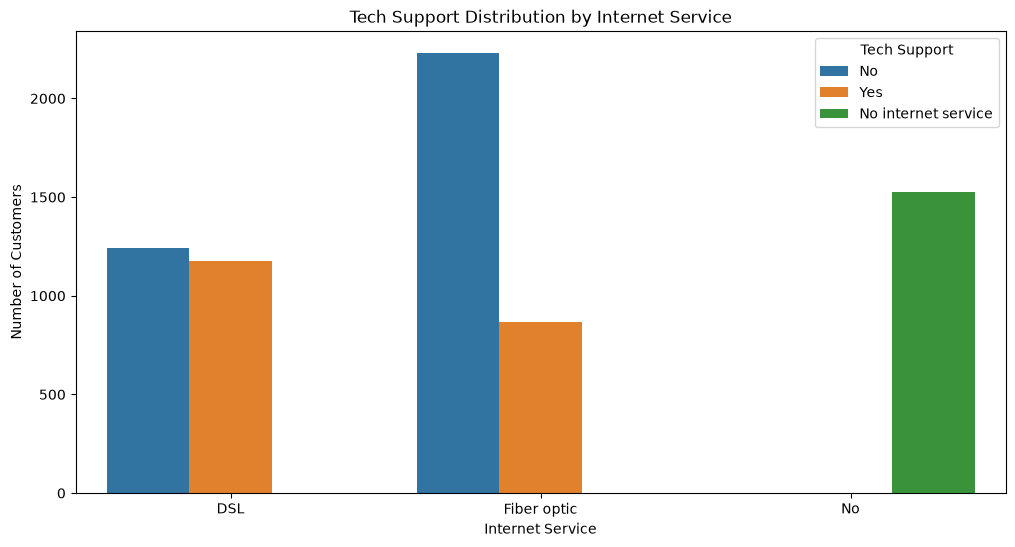

In [82]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Internet Service",
    hue="Tech Support"
)

plt.title("Tech Support Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.legend(title="Tech Support")
plt.show()

In [83]:
numeric_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Value",
    "Churn Score",
    "CLTV"
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
Tenure Months,1.000000,0.247900,0.825880,-0.352229,-0.224987,0.396406
Monthly Charges,0.247900,1.000000,0.651065,0.193356,0.133754,0.098693
Total Charges,0.825880,0.651065,1.000000,-0.199484,-0.124312,0.341837
Churn Value,-0.352229,0.193356,-0.199484,1.000000,0.664897,-0.127463
Churn Score,-0.224987,0.133754,-0.124312,0.664897,1.000000,-0.079782
CLTV,0.396406,0.098693,0.341837,-0.127463,-0.079782,1.000000


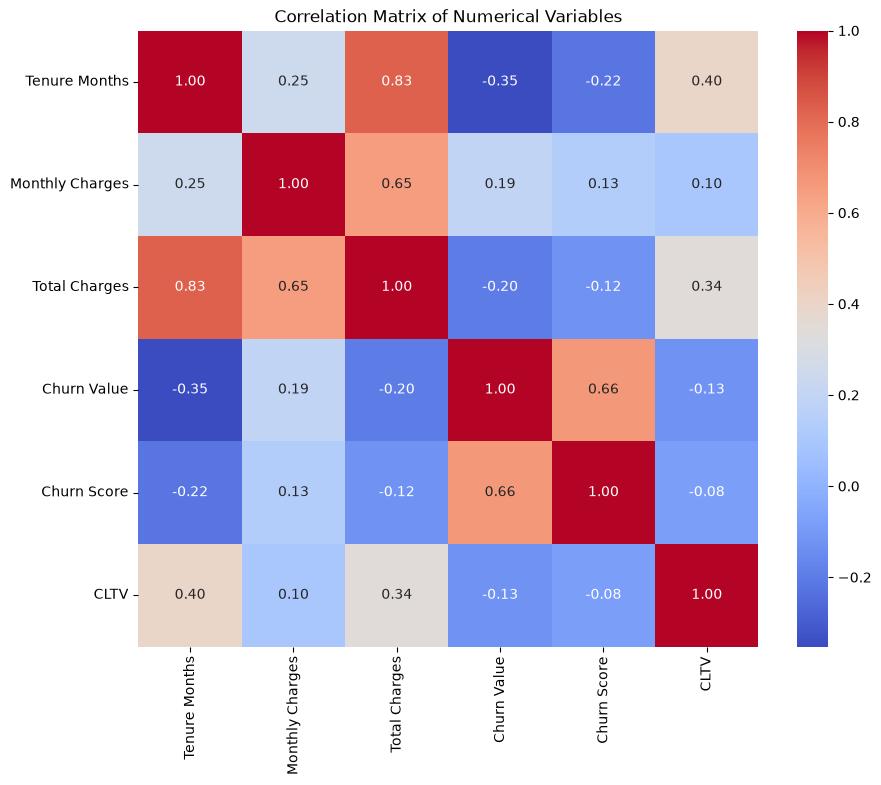

In [84]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

In [85]:
df[["City", "Zip Code", "Latitude", "Longitude"]].nunique()

City         1129
Zip Code     1652
Latitude     1652
Longitude    1651
dtype: int64

In [86]:
city_churn = (
    df.groupby("City")
    .agg(
        Customers=("CustomerID", "count"),
        Churn_Rate=("Churn Value", "mean")
    )
    .sort_values("Customers", ascending=False)
)

city_churn.head(20)

,Customers,Churn_Rate
City,,
Los Angeles,305,0.295082
San Diego,150,0.333333
San Jose,112,0.258929
Sacramento,108,0.240741
San Francisco,104,0.298077
Fresno,64,0.250000
Long Beach,60,0.250000
Oakland,52,0.250000
Stockton,44,0.272727


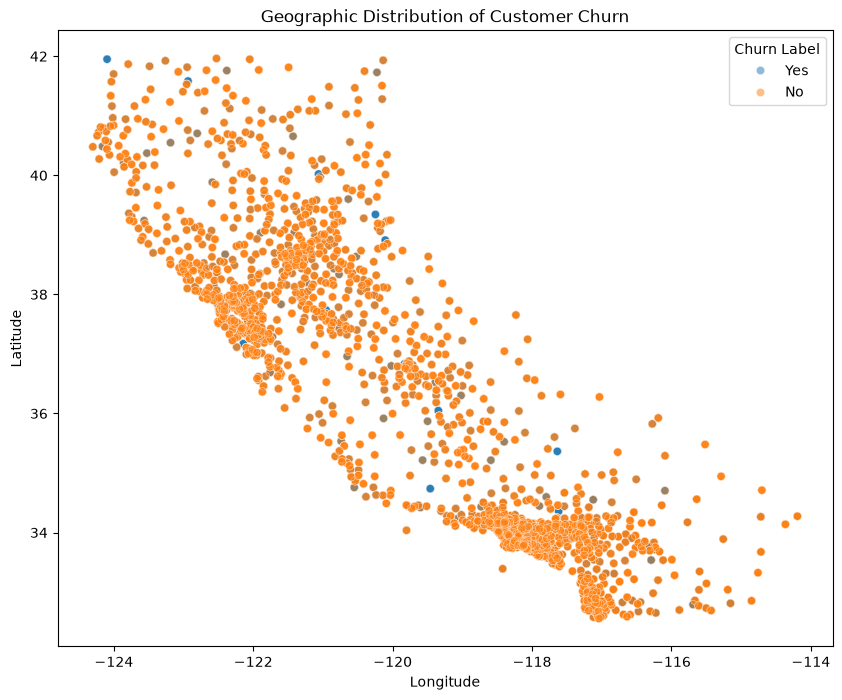

In [87]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue="Churn Label",
    alpha=0.5
)

plt.title("Geographic Distribution of Customer Churn")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [88]:
df["Lat_Bin"] = pd.cut(df["Latitude"], bins=10)
df["Long_Bin"] = pd.cut(df["Longitude"], bins=10)

geo_grid = pd.pivot_table(
    df,
    values="Churn Value",
    index="Lat_Bin",
    columns="Long_Bin",
    aggfunc="mean"
)

geo_grid

Long_Bin,"(-124.311, -123.291]","(-123.291, -122.28]","(-122.28, -121.269]","(-121.269, -120.258]","(-120.258, -119.247]","(-119.247, -118.236]","(-118.236, -117.225]","(-117.225, -116.215]","(-116.215, -115.204]","(-115.204, -114.193]"
Lat_Bin,,,,,,,,,,
"(32.546, 33.496]",NaN,NaN,NaN,NaN,NaN,0.400000,0.307692,0.287841,0.345455,0.25
"(33.496, 34.437]",NaN,NaN,NaN,NaN,0.375000,0.259172,0.249538,0.282528,0.280000,0.20
"(34.437, 35.378]",NaN,NaN,NaN,0.294118,0.308824,0.239130,0.292135,0.379310,0.272727,0.00
"(35.378, 36.318]",NaN,NaN,0.250000,0.218750,0.368421,0.240385,0.416667,0.250000,0.125000,NaN
"(36.318, 37.259]",NaN,0.250000,0.221154,0.166667,0.225490,0.283333,0.150000,NaN,NaN,NaN
"(37.259, 38.2]",NaN,0.296875,0.267241,0.302632,0.180556,0.100000,0.250000,NaN,NaN,NaN
"(38.2, 39.14]",0.218750,0.245455,0.285256,0.296610,0.312500,NaN,NaN,NaN,NaN,NaN
"(39.14, 40.081]",0.250000,0.230769,0.185484,0.272727,0.305556,NaN,NaN,NaN,NaN,NaN
"(40.081, 41.021]",0.235294,0.305556,0.308824,0.175000,0.125000,NaN,NaN,NaN,NaN,NaN


In [92]:
city_churn = (
    df.groupby("City")
    .agg(
        Customers=("CustomerID", "count"),
        Churn_Rate=("Churn Value", "mean")
    )
)

city_churn["Churn_Rate"] = city_churn["Churn_Rate"] * 100

city_churn.sort_values("Customers", ascending=False).head(20)

,Customers,Churn_Rate
City,,
Los Angeles,305,29.508197
San Diego,150,33.333333
San Jose,112,25.892857
Sacramento,108,24.074074
San Francisco,104,29.807692
Fresno,64,25.000000
Long Beach,60,25.000000
Oakland,52,25.000000
Stockton,44,27.272727


In [93]:
city_churn_reliable = city_churn[
    city_churn["Customers"] >= 20
].sort_values(
    "Churn_Rate",
    ascending=False
)

city_churn_reliable.head(20)

,Customers,Churn_Rate
City,,
Santa Rosa,24,45.833333
North Hollywood,20,45.000000
Modesto,28,42.857143
Santa Barbara,28,35.714286
San Diego,150,33.333333
Glendale,40,32.500000
Torrance,25,32.000000
Pasadena,30,30.000000
San Francisco,104,29.807692


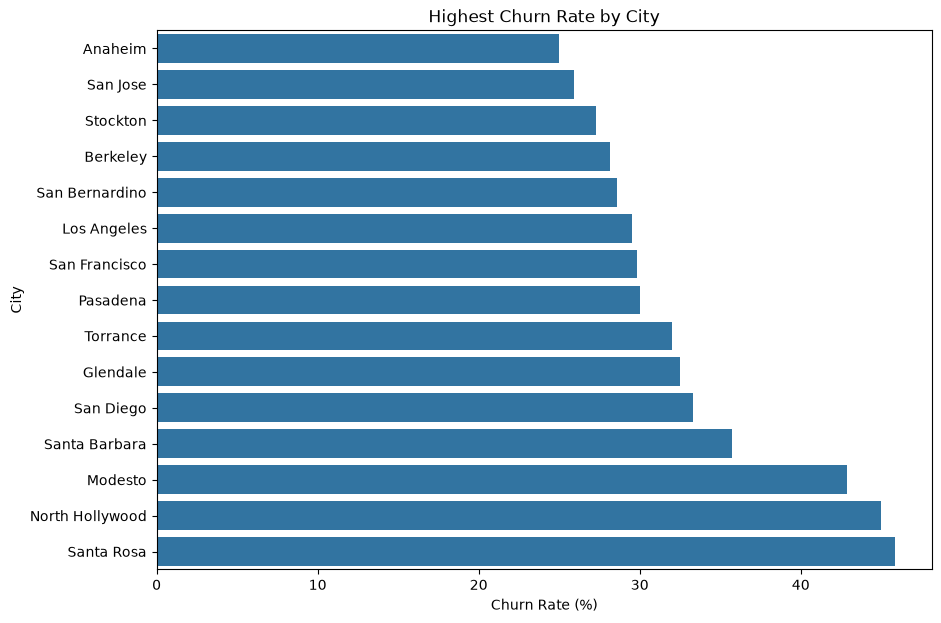

In [94]:
top_cities = city_churn_reliable.head(15).sort_values("Churn_Rate")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_cities.reset_index(),
    x="Churn_Rate",
    y="City"
)

plt.title("Highest Churn Rate by City")
plt.xlabel("Churn Rate (%)")
plt.ylabel("City")
plt.show()

ZIP-code churn analysis

In [99]:
zip_churn["Customers"].describe()

count    1652.000000
mean        4.263317
std         0.440566
min         4.000000
25%         4.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Customers, dtype: float64

In [100]:
zip_churn["Customers"].value_counts().sort_index()

Customers
4    1217
5     435
Name: count, dtype: int64

In [101]:
zip_churn_reliable = (
    zip_churn[
        zip_churn["Customers"] >= 4
    ]
    .sort_values("Churn_Rate", ascending=False)
)

zip_churn_reliable.head(20)

,Zip Code,Customers,Churn_Rate
481,92397,4,100.0
1564,96032,4,100.0
635,93110,4,100.0
672,93252,4,100.0
1077,95006,4,100.0
1338,95567,4,100.0
842,93711,4,100.0
1223,95367,4,100.0
18,90020,5,100.0
1651,96161,4,100.0


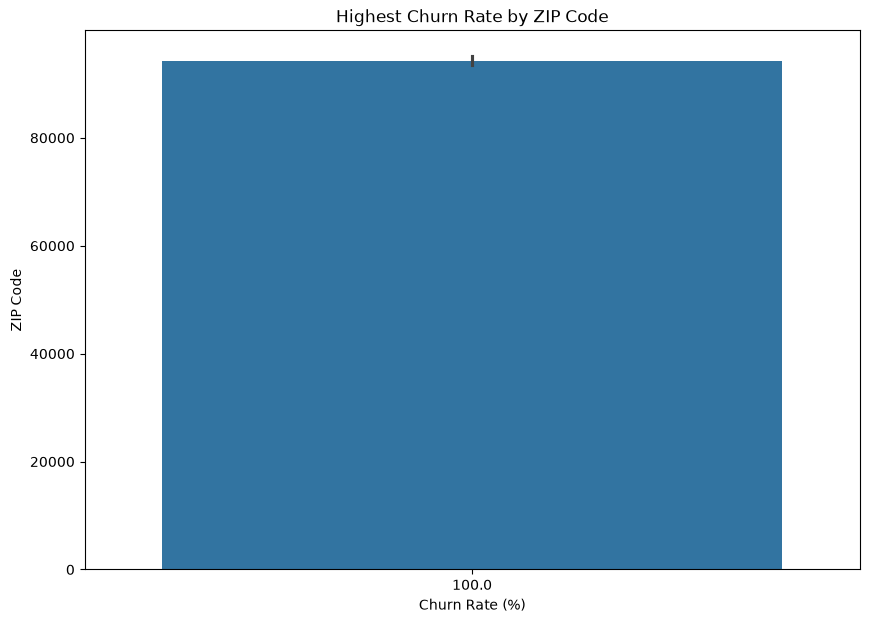

In [102]:
top_zip = zip_churn_reliable.head(15).sort_values("Churn_Rate")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_zip,
    x="Churn_Rate",
    y="Zip Code"
)

plt.title("Highest Churn Rate by ZIP Code")
plt.xlabel("Churn Rate (%)")
plt.ylabel("ZIP Code")
plt.show()

In [103]:
geo_unique = df[
    ["City", "Zip Code", "Latitude", "Longitude"]
].nunique()

geo_unique

City         1129
Zip Code     1652
Latitude     1652
Longitude    1651
dtype: int64

In [104]:
geo_summary = df[
    ["Latitude", "Longitude"]
].describe()

geo_summary

,Latitude,Longitude
count,7043.000000,7043.000000
mean,36.282441,-119.798880
std,2.455723,2.157889
min,32.555828,-124.301372
25%,34.030915,-121.815412
50%,36.391777,-119.730885
75%,38.224869,-118.043237
max,41.962127,-114.192901


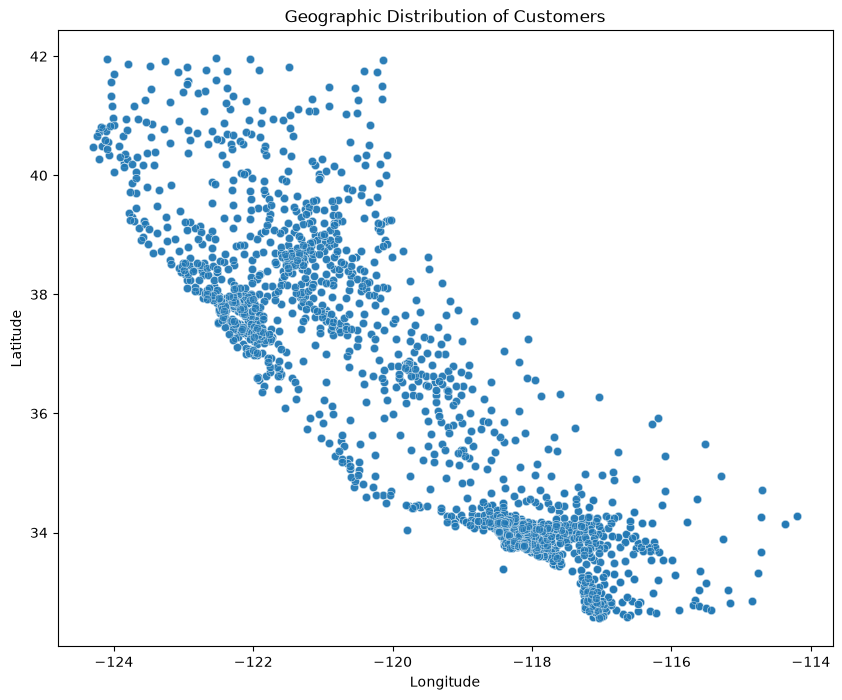

In [105]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    alpha=0.5
)

plt.title("Geographic Distribution of Customers")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

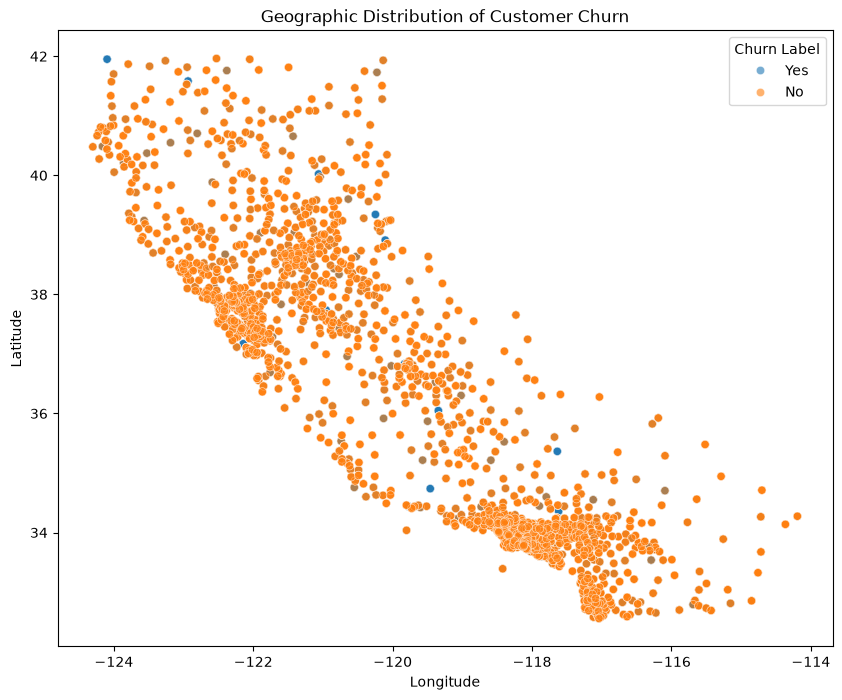

In [106]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue="Churn Label",
    alpha=0.6
)

plt.title("Geographic Distribution of Customer Churn")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [107]:
df["Lat_Bin"] = pd.cut(
    df["Latitude"],
    bins=10
)

df["Long_Bin"] = pd.cut(
    df["Longitude"],
    bins=10
)

In [108]:
geo_grid = pd.pivot_table(
    df,
    values="Churn Value",
    index="Lat_Bin",
    columns="Long_Bin",
    aggfunc="mean"
)

geo_grid

Long_Bin,"(-124.311, -123.291]","(-123.291, -122.28]","(-122.28, -121.269]","(-121.269, -120.258]","(-120.258, -119.247]","(-119.247, -118.236]","(-118.236, -117.225]","(-117.225, -116.215]","(-116.215, -115.204]","(-115.204, -114.193]"
Lat_Bin,,,,,,,,,,
"(32.546, 33.496]",NaN,NaN,NaN,NaN,NaN,0.400000,0.307692,0.287841,0.345455,0.25
"(33.496, 34.437]",NaN,NaN,NaN,NaN,0.375000,0.259172,0.249538,0.282528,0.280000,0.20
"(34.437, 35.378]",NaN,NaN,NaN,0.294118,0.308824,0.239130,0.292135,0.379310,0.272727,0.00
"(35.378, 36.318]",NaN,NaN,0.250000,0.218750,0.368421,0.240385,0.416667,0.250000,0.125000,NaN
"(36.318, 37.259]",NaN,0.250000,0.221154,0.166667,0.225490,0.283333,0.150000,NaN,NaN,NaN
"(37.259, 38.2]",NaN,0.296875,0.267241,0.302632,0.180556,0.100000,0.250000,NaN,NaN,NaN
"(38.2, 39.14]",0.218750,0.245455,0.285256,0.296610,0.312500,NaN,NaN,NaN,NaN,NaN
"(39.14, 40.081]",0.250000,0.230769,0.185484,0.272727,0.305556,NaN,NaN,NaN,NaN,NaN
"(40.081, 41.021]",0.235294,0.305556,0.308824,0.175000,0.125000,NaN,NaN,NaN,NaN,NaN


In [109]:
geo_grid_percentage = geo_grid * 100

geo_grid_percentage

Long_Bin,"(-124.311, -123.291]","(-123.291, -122.28]","(-122.28, -121.269]","(-121.269, -120.258]","(-120.258, -119.247]","(-119.247, -118.236]","(-118.236, -117.225]","(-117.225, -116.215]","(-116.215, -115.204]","(-115.204, -114.193]"
Lat_Bin,,,,,,,,,,
"(32.546, 33.496]",NaN,NaN,NaN,NaN,NaN,40.000000,30.769231,28.784119,34.545455,25.0
"(33.496, 34.437]",NaN,NaN,NaN,NaN,37.500000,25.917160,24.953789,28.252788,28.000000,20.0
"(34.437, 35.378]",NaN,NaN,NaN,29.411765,30.882353,23.913043,29.213483,37.931034,27.272727,0.0
"(35.378, 36.318]",NaN,NaN,25.000000,21.875000,36.842105,24.038462,41.666667,25.000000,12.500000,NaN
"(36.318, 37.259]",NaN,25.000000,22.115385,16.666667,22.549020,28.333333,15.000000,NaN,NaN,NaN
"(37.259, 38.2]",NaN,29.687500,26.724138,30.263158,18.055556,10.000000,25.000000,NaN,NaN,NaN
"(38.2, 39.14]",21.875000,24.545455,28.525641,29.661017,31.250000,NaN,NaN,NaN,NaN,NaN
"(39.14, 40.081]",25.000000,23.076923,18.548387,27.272727,30.555556,NaN,NaN,NaN,NaN,NaN
"(40.081, 41.021]",23.529412,30.555556,30.882353,17.500000,12.500000,NaN,NaN,NaN,NaN,NaN


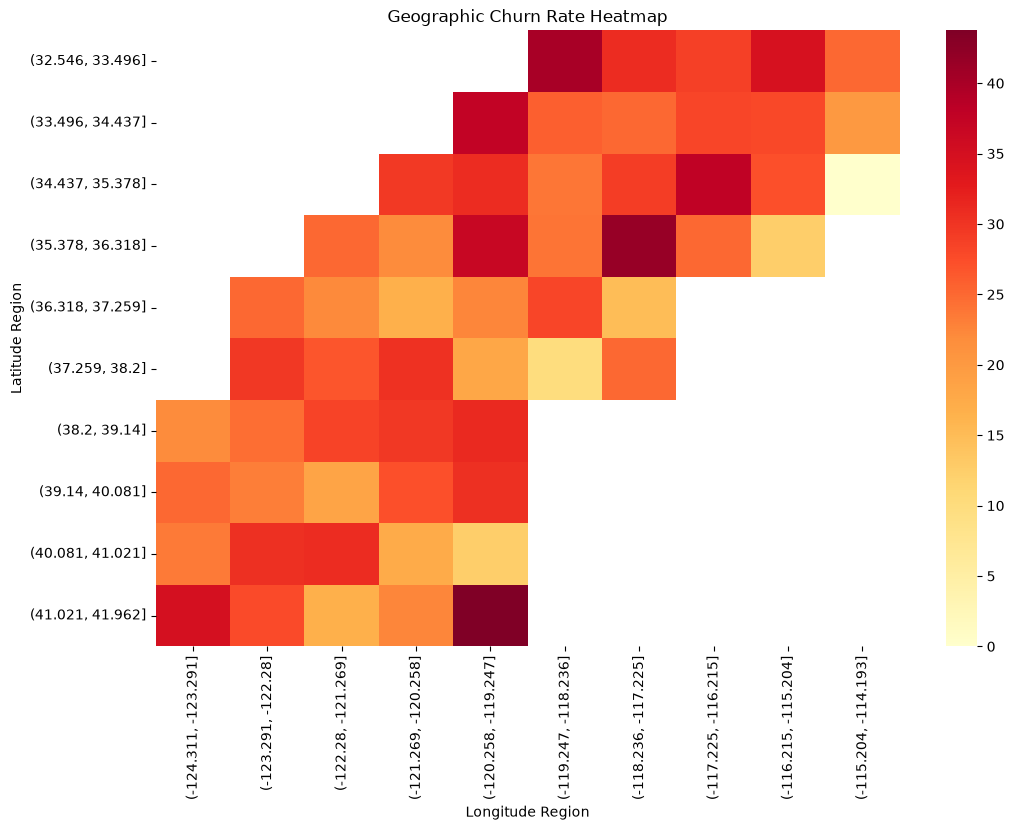

In [110]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    geo_grid_percentage,
    annot=False,
    cmap="YlOrRd"
)

plt.title("Geographic Churn Rate Heatmap")
plt.xlabel("Longitude Region")
plt.ylabel("Latitude Region")
plt.show()